# AMC 2026 – Round 3 · Notebook: a tactical deviation with quantitative investing
Financial Modeling (USI) · TA session 6

## Goal of today
Starting from the Round 2 portfolio, add a **quantitative factor strategy** (Class 6): specify it, backtest it with the **Class 4 protocol**, and size it inside the **tracking-error budget**. 

The data come from `r3_bloomberg.xlsx` → `01_bloomberg_data.ipynb` (CSV files in this folder).

## The Round 3 guidelines (recap)
**Key dates**

| When | What |
|---|---|
| Sat 28 – Sun 29 November | insert the new positions in Bloomberg (**PRTU**): prices of **Friday 27 November** |
| **Sun 29 November, 23:59** | report + code + portfolio description; upload them to your fund's website |
| Tue 1 Dec 11:00 (room 253) · Thu 3 Dec 13:30 (SI-008) | presentations, **15 minutes**, all members |
| until **27 December** | the portfolio cannot change: this is the last round |

**The task**
- Add **two** tactical strategies, the portfolio must contain **both**:
  - a **quantitative** strategy, based on factors such as value, momentum, quality, low beta,... or a combinations of them (**Class 6**);
  - a **macro** strategy: yield curve, currencies, commodities, country value/momentum, or a global theme (**Class 7**).
- **Long-only** stocks.
- The **SAA of Round 1 does not change**: it is the reference for all the deviations.
- **Round 2 stocks:** keep or close each one, and say why (catalyst occurred? valuation still holds?).

**The tracking-error budget**
- **Ex-ante TE against the SAA ≤ 7% per year**, for all the deviations **together**: the Round 2 stocks you keep + the quant strategy + the macro strategy.
- Same convention as before: **monthly returns in USD, annualized, last 60 months** where available.
- Report the ex-ante **volatility** and the **one-month 5% VaR** of the portfolio.


**The report** has three parts:
1. **Analysis of the two strategies:** for each, (i) why it should be profitable in the coming weeks, (ii) the anomaly it exploits: **risk compensation or behavioural** explanation, (iii) the risks it is exposed to.
2. **Performance of Round 2** (start of Round 2 → Fri 27 Nov): return, volatility, Sharpe; the contribution of the deviation (portfolio vs the SAA alone); **performance attribution** (PORT or own computation); for each Round 2 stock: catalyst occurred? kept or closed?
3. **Checkpoint assignments** (graded complete / incomplete):
   - **Checkpoint 1, quant strategy specification (Class 6, Part I):** the factor and its economic rationale; the **construction rule** (signal, universe, weighting, rebalancing); the **backtest** with the **Class 4 protocol**: design, validation, risk, discount.
   - **Checkpoint 2, macro strategy (Class 7).**

**Portfolio description:** the complete portfolio and the **list of trades**; (see guidelines).

**Bloomberg:** **update** the existing portfolio with PRTU (do **not** create a new one); it stays shared with the TA, must equal the portfolio in the report, and cannot change until the end.

## Where each requirement is in this notebook
| Requirement | Section |
|---|---|
| Checkpoint 1: factor and rationale | §1 |
| Checkpoint 1: construction rule (long-only) | §2 |
| Checkpoint 1: backtest — design, validation, risk, discount | §3, §4, §5, §6 |
| Today's stocks | §7 |
| Round 2 stocks: keep or close; Round 2 performance | §0 (`KEEP_R2`) |
| TE ≤ 7%, volatility and VaR vs the SAA | §8 |
| Portfolio description and trades | §9 |
| Checkpoint 2 (macro) | next week (Class 7) |


## 0. Settings

In [1]:
import numpy as np                     # arrays and matrix algebra
import pandas as pd                    # tables with dates
import matplotlib.pyplot as plt        # plots
pd.set_option("display.float_format", "{:.4f}".format)

# SAA of Round 1 (each group uses its own SAA here)
W_SAA = pd.Series({"SPY": 0.086, "EFA": 0.074, "EEM": 0.070, "IEF": 0.177,
                   "LQD": 0.124, "TIP": 0.200, "GLD": 0.097, "DBC": 0.159})   # the rest (1.3%) is cash
ETFS = list(W_SAA.index)

# Round 2 portfolio (TA example, notebook 02_round2_lecture)   ⚠️ take YOUR shares and cash from PORT
OLD_SHARES = pd.Series({"SPY": 9077, "EFA": 58302, "EEM": 90211, "IEF": 158431, "LQD": 96792,
                        "TIP": 153300, "GLD": 21309, "DBC": 381563, "GIS": 561066})
CASH_R2 = 1_058_793
KEEP_R2 = {"GIS": True}                # ⚠️ keep/close each Round 2 stock, justified by its catalyst. TA example: GIS kept, to show how a Round 2 bet uses part of the TE budget

WINDOW   = 60                          # months, as in Rounds 1 and 2
SPLIT    = "2015-12-31"                # Class 4: tune on 2006-2015, validate on 2016-2026
N_EXTRA  = 0                           # ⚠️ Class 4: backtests you ran but did NOT paste in the Excel (the others are counted in §4)
DISCOUNT = 0.5                         # Class 4 rule of thumb: divide the backtested Sharpe Ratio by 2
TE_MAX, TE_QUANT = 0.07, 0.05          # Round 3 budget, and the TE we use before the macro strategy

## 1. The factors and their rationale (Checkpoint 1, part 1)
A **factor** is a characteristic of a stock that helps predict its return: sort many stocks on it, and the top group earns more than the bottom group on average.

The checkpoint asks **why** it should earn more. Two possible answers:

| | **Risk** | **Behavioural** |
|---|---|---|
| Idea | a payment for holding a risk investors dislike | a profit from a mistake investors keep making |
| Example | cheap firms crash in recessions, so they must pay more | investors overreact to bad news, so prices fall too low |
| Will it last? | yes, as long as the risk exists | only while the mistake lasts and is hard to trade away |

Our strategy is **"cheap, profitable stocks on the rise"**: a composite of three factors.

### 1a. Value: buy cheap stocks
- **Signal:** the price-to-book ratio ($P/B$). It compares what the market pays for a firm with what the firm owns on its balance sheet. A low $P/B$ means the stock is cheap.
- **Evidence:** cheap stocks have beaten expensive ones over the long run (Fama-French HML, Sharpe 0.34 since 1927, Class 6, Exercise A). But since 2009 the effect has been weak (Exercise B: alpha −2.1%, not significant).
- **Why it should pay (risk):** cheap firms are often in trouble. They suffer most in recessions, exactly when investors need money. Investors want extra return to hold them.
- **Why it should pay (behaviour):** after a run of bad news, investors become too pessimistic and push the price too low. When the news turns out less bad than feared, the price recovers.
- **Main risk:** the **value trap** (Class 5). Some stocks are cheap for a good reason: their profits are about to fall. They stay cheap, or get cheaper.

### 1b. Quality: buy profitable stocks
- **Signal:** return on assets, $ROA = \dfrac{\text{net income}}{\text{total assets}}$. It tells how much profit a firm makes with each dollar it has invested. A high ROA means a good business.
- **Logic:** buy good firms.
- **Why it should pay (risk):** hard to argue. Profitable firms are *less* risky, so their extra return is not a reward for risk.
- **Why it should pay (behaviour):** investors chase exciting stories and ignore boring, profitable firms. So these firms end up too cheap.
- **Main risk:** in rebounds after a crash, the weakest stocks rise most and quality lags the market.

### 1c. Momentum: buy recent winners
- **Signal:** the total return of the last 12 months (EQS: `Total Return 1 Year`). The winners are the stocks with the highest return. *(Academics skip the last month, which tends to reverse.)*
- **Evidence:** the Mom factor: Sharpe 0.46 since 1927, alpha 9.9% with t = 6.4 (Class 6, Exercise B).
- **Risk story:** hard to defend: the stocks in the portfolio change every month, so it is hard to name one stable risk they are paid for.
- **Behavioural story:** investors react slowly to news, so prices keep moving in the same direction for a while; then others jump on the trend and push it further.
- **Main risk:** **momentum crashes**. After a big fall, when the market suddenly bounces back, the past losers rise the most and the winners we hold fall behind (Exercise C: August 1932 −52.6%, April 2009 −34.4%).

### 1e. Low volatility: buy the calmest stocks
- **Signal:** the volatility of daily returns over the last year (EQS: `Volatility 260 Day`). **Low** volatility = high rank.
$$\sigma_i = \text{sd}\big(r_{i,d}\big)\cdot\sqrt{260}, \qquad r_{i,d} = \text{daily return of stock } i \text{ over the last 260 trading days}$$
- **Evidence:** in theory riskier stocks should earn more, but in the data they don't: calm stocks earn about the same as risky ones, with much less risk (Class 6, *Betting against beta*, Frazzini and Pedersen, 2014).
- **Risk story:** weak: these stocks are *less* risky, so the extra return is not a reward for risk.
- **Behavioural story:** many investors cannot borrow, so to aim for high returns they buy risky, "exciting" stocks. These become too expensive, and the calm ones too cheap.
- **Main risk:** calm stocks (utilities, food, healthcare) behave a bit like bonds: they suffer when interest rates rise, and earn less than the market in strong rallies.

### 1f. Low beta: buy the stocks that move less with the market
- **Signal:** the beta of each stock against the market (EQS: Fields → `beta`). **Low** beta = high rank.
$$\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}$$
  $\beta_i = 0.6$: when the market moves 1%, the stock moves on average 0.6%.
- **Evidence:** same as low volatility: low-beta stocks earn more than the CAPM predicts, high-beta stocks less (Frazzini and Pedersen, 2014).
- **Risk story:** weak, for the same reason as low volatility.
- **Behavioural story:** investors who cannot borrow buy high-beta stocks to get more market exposure, and push their prices up.
- **Main risk:** the portfolio has a beta below 1, so in a strong bull market it earns less than the index. Betas are also noisy estimates.

### 1g. Low accruals: buy firms whose profits are made of cash
- **Signal:** the part of profits that is **not** cash, scaled by the size of the firm. **Low** accruals = high rank.
$$\text{Accruals}_i = \frac{\text{Net income}_i - \text{Cash flow from operations}_i}{\text{Total assets}_i}$$
- **Evidence:** firms with high accruals earn lower returns the following year (Sloan, 1996).
- **Behavioural story:** profits that are not yet cash (unpaid invoices, unsold inventory) are less likely to repeat. Investors look only at total profits, miss the difference, and over-price these firms. When the accruals reverse, profits disappoint.
- **Link with the course:** it is the free-cash-flow check of the Round 2 value-trap dossier, turned into a rule.
- **Main risk:** accounting differs a lot across industries; banks and insurers are usually excluded.

### 1h. Profitability: buy firms with a high gross profit
- **Signal:** gross profit per dollar of assets. **High** = high rank.
$$GP_i = \frac{\text{Revenue}_i - \text{Cost of goods sold}_i}{\text{Total assets}_i}$$
- **Evidence:** more profitable firms earn higher returns, and the effect is strong when combined with value (Novy-Marx, 2013).
- **Why gross profit and not ROA?** It sits at the top of the income statement, so it is less affected by accounting choices and one-off items.
- **Behavioural story:** as for quality: steady, profitable firms are boring and get overlooked.
- **Main risk:** it does not work for banks (no "gross profit"); like quality, it earns less than the market in junk rallies after a crash.

### 1j. Investment: buy firms that grow their assets slowly
- **Signal:** the growth of total assets over the last year. **Low** growth = high rank.
$$INV_i = \frac{\text{Total assets}_{i,t}}{\text{Total assets}_{i,t-1}} - 1$$
- **Evidence:** firms that invest aggressively earn lower returns afterwards; it is the "CMA" factor of the Fama-French five-factor model (Fama and French, 2015).
- **Risk story:** firms invest a lot when their cost of capital is low, i.e. when investors require a low return.
- **Behavioural story:** managers of fast-growing firms over-invest (empire building), and investors are too optimistic about their growth.
- **Main risk:** it overlaps with value (cheap firms tend to invest little), so it adds less when combined with P/B.

**Other factors.** These are only examples: the literature has documented hundreds of factors (Harvey, Liu and Zhu, 2016, count more than 300). Feel free to explore others, as long as you can explain **why** they should earn a return (risk or behavioural story) and build them in Bloomberg.

⚠️ **Every factor you try is one more backtest.** If you test many ideas and keep the best one, some of its good result is just luck (Class 4: with 20 tries and no real effect, about 1 looks significant at 5%). So write down every backtest you run (§4), and the more you tried, the more you must discount the backtest Sharpe Ratio (§6).

### 1d. Why combine them, and why now
**Diversification (Class 6, Exercise A, Jan 1927 – Sep 2026):**

| | Mean | Volatility | Sharpe |
|---|---|---|---|
| Value (HML) | 4.2% | 12.3% | 0.34 |
| Momentum (Mom) | 7.4% | 16.3% | 0.46 |
| **50/50 combination** | 5.8% | **8.0%** | **0.73** |

Value and momentum have a correlation of **−0.41**: they lose at different times, so the combination has half the volatility and a higher Sharpe than either. The factors also **help each other**:
- **Momentum is the catalyst of value:** value says *what* is cheap, momentum says the market has *started* to notice. A cheap stock whose price is already rising is less likely to be a value trap.
- **Quality is the value-trap filter:** it removes the cheap stocks whose profits are bad.
- Value + quality + momentum together: Sharpe ≈ 0.80 in the Class 6 reading.



## 2. The construction rule (Checkpoint 1, part 2)
**Step 1: from three signals to one score.** The signals have different units ($P/B$ is a ratio, ROA a percentage, momentum a return), so we cannot add them. We turn each into a **percentile rank** within the universe: 100 = best stock on that signal, 1 = worst. For value, "best" = the **lowest** $P/B$. The **score** is the average of the three ranks:

$$\text{score}_i = \tfrac{1}{3}\big[\text{rank}_i(\text{cheap } P/B) + \text{rank}_i(ROA) + \text{rank}_i(\text{1-year return})\big]$$

**Step 2: My rule.**

| Choice | Our rule |
|---|---|
| Universe | **Russell 1000** |
| Signal | the score above |
| **Long-only** | hold the stocks with a score rank **≥ 98** (top 2%) |
| Weighting | **equal weights** |
| Rebalancing | **monthly** |

- **Long-only limitation:** Academic factors typically use a long-short strategy: buy the best stocks and short the worst. In the AMC, we cannot short, so we only buy the best stocks and avoid the worst, meaning we underweight them relative to the market.

**Step 3: in Bloomberg (EQS → Formula tab, as in the Class 4 reading appendix).** `PERCENTILERANK(field, lower is better?, whole universe, break ties, number of groups)`, one line per expression:

> 📄 **Step-by-step guide:** *AMC 2026 Round 3 - Building factors in Bloomberg.pdf* (in this folder) explains how to build the ranks, the score, the screen and the backtest in Bloomberg, with one card for each factor of §1. The table below is the short version for our V+M+Q rule.

| Line | Expression | Meaning |
|---|---|---|
| EXP1 → EXP2 | `PX_TO_BOOK_RATIO` → `PERCENTILERANK(EXP1, Y, Y, Y, 100)` | value rank (**Y** = lower P/B is better) |
| EXP3 → EXP4 | `RETURN_ON_ASSET(FUND_PER='LTM')` → `PERCENTILERANK(EXP3, N, Y, Y, 100)` | quality rank (last 12 months ROA) |
| EXP5 → EXP6 | `TOTAL_RETURN(CALC_INTERVAL='1Y')` → `PERCENTILERANK(EXP5, N, Y, Y, 100)` | momentum rank |
| EXP7 | `(EXP2 + EXP4 + EXP6) / 3` | the score |
| EXP8 | `PERCENTILERANK(EXP7, N, Y, Y, 100)` | the score as a rank: the screen keeps **≥ 98** |

**Saving it in Bloomberg.**
1. Save the eight lines as one formula, called `VQM score` (its output is EXP8, the final rank).
2. Build the screen **AMC R3 VMQ** with two lines, in this order: **(1)** universe = Russell 1000, **(2)** `VQM score ≥ 98`. On 11 Nov 2026 it returns **29 stocks**: this is our portfolio.
3. ⚠️ **Why the order matters:** EQS applies the lines from top to bottom, and each rank is computed only among the stocks still in the list at that point. With the Russell 1000 first, "rank ≥ 98" means "top 2% of the Russell 1000"; otherwise the ranks would be computed on a different universe.
4. To test each factor **on its own**, we saved three more screens, identical except that they use a single rank: `V rank ≥ 98`, `M rank ≥ 98`, `Q rank ≥ 98` → **AMC R3 V**, **AMC R3 M**, **AMC R3 Q**. These give the single-factor backtests.



### 2b. Make it yours: where your group puts its views
Each row is a choice that your group must make **and justify** in Checkpoint 1:

| Knob | My choice | What your group could do instead |
|---|---|---|
| **Factors** | P/B, ROA, 1-year return | E/P, gross profitability, 12-1 momentum, low volatility, accruals,.... (§1e) |
| **Weights of the factors** | 1/3 each | e.g. 50% momentum, if you believe more in it in the coming month |
| **Universe** | Russell 1000 | S&P 500, ex-financials, ex-energy, one region |
| **Selection** | score rank ≥ 98 (~30 stocks) | e.g top 50, top decile (more breadth, less tilt) |
| **Sector view** | none  | rank **within** sectors, or cap each sector |
| **Weighting** | equal | market cap (more liquid, closer to the index), score-weighted, ... |


- ⚠️ **Every adjustment counts as a trial** (Class 4): Record it in §4 (`N_EXTRA`). More trials mean a larger discount in §6. 

## 3. The backtest: design and results (Checkpoint 1, part 3)

**How we test it:** What would have happened if we had followed this strategy over the last 20 years?

- `EQBT` backtests the strategy from October 2006 to October 2026.
- Each month, we rank Russell 1000 stocks using only information available at that time, buy the top ~30 in equal weights, and hold for one month.
- This avoids **survivorship bias** (using today's index members) and **look-ahead bias** (using future information).
- We compare performance against the Russell 1000 (`RIY Index`) and test each factor separately (Value, Momentum, Quality).

**What we look at** (Classes 2 and 4):

- **Return and risk:** Annualized return, volatility, maximum drawdown, and 5% monthly VaR.
- **Sharpe Ratio:** Return per unit of risk. Its t-statistic tells us whether the average excess return is statistically significant (typically |t| > 2).
- **Alpha and Beta:** Beta measures market exposure, while alpha measures the return not explained by the market.
- **Information Ratio (IR):** Alpha per unit of residual risk.

$$SR = \frac{\overline{R - r_f}\cdot 12}{\text{sd}(R)\sqrt{12}}, \qquad t(\bar R^e) = SR\sqrt{T_{years}}, \qquad R^e_t = \alpha + \beta R^e_{B,t} + \varepsilon_t, \qquad IR = \frac{\alpha}{\sigma(\varepsilon)}, \qquad t(\alpha) = IR\sqrt{T_{years}}$$

BACKTEST Nov 2006 - Oct 2026 (240 months). One column per strategy:
  mean, vol      : annualized return and volatility
  Sharpe, t(mean): excess return per unit of risk; t > 2 = unlikely to be luck
  max drawdown   : worst fall from a peak; VaR 5% 1m: loss in a bad month (1 in 20)
  beta, alpha    : CAPM on the Russell 1000; alpha = return beyond the market exposure
  IR, t(alpha)   : alpha per unit of extra risk; t > 2 = alpha distinguishable from zero


,V+M+Q,Value,Momentum,Quality,Russell 1000
mean,0.1167,0.1572,0.1433,0.1255,0.1163
vol,0.1992,0.3985,0.2644,0.1863,0.1558
Sharpe,0.5078,0.3555,0.4834,0.5900,0.6471
t(mean),2.2712,1.5899,2.1617,2.6385,2.8939
max drawdown,-0.6256,-0.8778,-0.6348,-0.5538,-0.5111
VaR 5% 1m,0.0946,0.1892,0.1256,0.0885,0.0740
beta,1.0715,1.8890,1.2371,1.0724,1.0000
alpha,-0.0069,-0.0488,0.0031,0.0018,0.0000
IR,-0.0634,-0.1808,0.0171,0.0222,NaN
t(alpha),-0.2834,-0.8084,0.0764,0.0991,NaN



CHART: growth of USD 1 invested in each strategy (log scale, so equal slopes = equal returns).
Left of the dashed line (2015-12-31) = design sample; right = validation, the honest test.


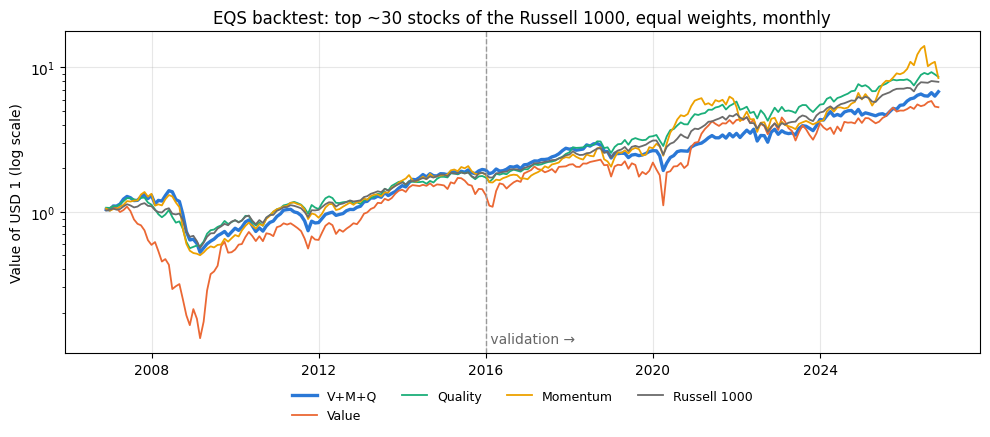

In [2]:
bt = pd.read_csv("r3_backtest.csv", index_col=0, parse_dates=True)    # EQS backtest, monthly returns
rf = pd.read_csv("r3_rf.csv", index_col=0, parse_dates=True)["rf"].reindex(bt.index).ffill()
BENCH = "Russell 1000"

def stats(r, rf, bench):
    # Class 2 / Class 4 measures of monthly returns r
    ex, exb = r - rf, bench - rf
    T = len(r) / 12                                                   # years
    beta, a = np.polyfit(exb, ex, 1)                                  # CAPM: R^e = a + beta R^e_B + e
    eps = ex - a - beta * exb
    IR  = a * 12 / (eps.std() * np.sqrt(12)) if eps.std() > 0 else np.nan
    if r.equals(bench):                                               # the benchmark against itself
        beta, a, IR = 1.0, 0.0, np.nan
    wealth = (1 + r).cumprod()
    return pd.Series({"mean": r.mean() * 12, "vol": r.std() * np.sqrt(12),
                      "Sharpe": ex.mean() / r.std() * np.sqrt(12), "t(mean)": ex.mean() / r.std() * np.sqrt(12) * np.sqrt(T),
                      "max drawdown": (wealth / wealth.cummax() - 1).min(), "VaR 5% 1m": 1.645 * r.std(),
                      "beta": beta, "alpha": a * 12, "IR": IR, "t(alpha)": IR * np.sqrt(T)})

res = bt.apply(lambda r: stats(r, rf, bt[BENCH]))

print(f"BACKTEST {bt.index[0]:%b %Y} - {bt.index[-1]:%b %Y} ({len(bt)} months). One column per strategy:")
print("  mean, vol      : annualized return and volatility")
print("  Sharpe, t(mean): excess return per unit of risk; t > 2 = unlikely to be luck")
print("  max drawdown   : worst fall from a peak; VaR 5% 1m: loss in a bad month (1 in 20)")
print("  beta, alpha    : CAPM on the Russell 1000; alpha = return beyond the market exposure")
print("  IR, t(alpha)   : alpha per unit of extra risk; t > 2 = alpha distinguishable from zero")
display(res)

print("\nCHART: growth of USD 1 invested in each strategy (log scale, so equal slopes = equal returns).")
print(f"Left of the dashed line ({SPLIT}) = design sample; right = validation, the honest test.")

colors = {"V+M+Q": "#2a78d6", "Value": "#eb6834", "Quality": "#1baf7a", "Momentum": "#eda100",
          "Low volatility": "#e87ba4", "Low accruals": "#6250d6", "5 factors": "#008300", BENCH: "#6b6b6b"}
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, c in colors.items():
    if k in bt:
        ax.plot((1 + bt[k]).cumprod(), color=c, lw=2.4 if k == "V+M+Q" else 1.3, label=k)
ax.axvline(pd.Timestamp(SPLIT), color="#999", ls="--", lw=1)
ax.text(pd.Timestamp(SPLIT), 0.03, " validation →", transform=ax.get_xaxis_transform(), color="#666")
ax.set_yscale("log"); ax.set_ylabel("Value of USD 1 (log scale)"); ax.grid(alpha=.3)
ax.set_title("EQS backtest: top ~30 stocks of the Russell 1000, equal weights, monthly")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

## 4. Validation (Checkpoint 1, part 3)

1. **Split the sample:** Use 2006–2015 to develop and tune the strategy. Freeze the rules at the end of 2015, then test them on 2016–2026 without further adjustments.
2. **Count the trials:** The more strategies we test, the more likely we are to find good results by chance. Even with no true alpha, about 1 in 20 tests may appear significant at the 5% level. So keep track of every backtest you run.

In [3]:
periods = {"tuning 2006-2015": bt.loc[:SPLIT], "validation 2016-2026": bt.loc[SPLIT:].iloc[1:]}
val = pd.concat({p: x.apply(lambda r: stats(r, rf.loc[r.index], x[BENCH]))[["V+M+Q", BENCH]] for p, x in periods.items()}, axis=1)
N_VARIATIONS = bt.shape[1] - 1 + N_EXTRA                             # every strategy column + the runs not pasted
print(f"Variations tried: {N_VARIATIONS}  (with 20 variations and zero alpha, ~1 would look significant at 5%)")
val.loc[["mean", "vol", "Sharpe", "alpha", "t(alpha)", "max drawdown"]]

Variations tried: 4  (with 20 variations and zero alpha, ~1 would look significant at 5%)


tuning 2006-2015              validation 2016-2026             
                        V+M+Q Russell 1000                V+M+Q Russell 1000
mean                   0.0969       0.0788               0.1334       0.1481
vol                    0.2147       0.1590               0.1858       0.1530
Sharpe                 0.4182       0.4510               0.5964       0.8197
alpha                  0.0044       0.0000              -0.0104       0.0000
t(alpha)               0.1333          NaN              -0.3042          NaN
max drawdown          -0.6256      -0.5111              -0.3497      -0.2459

**Reading the results:**
- **Tuning (2006–2015):** Small positive alpha of +0.4% (t = 0.1).
- **Validation (2016–2026):** Alpha turns negative (−1.0%, t = −0.3), with a Sharpe of 0.60 versus 0.82 for the index.
- **Interpretation:** Performance worsens out of sample, but neither alpha is statistically significant. We cannot conclude that the strategy beats the market.
- **Trials:** We ran 4 backtests (V+M+Q, V, M, Q). Record any additional tests in `N_EXTRA`.

**Reading the results:**
- **The worst months are all market crashes** (Sep–Oct 2008, Sep 2011, Mar 2020, Jun 2022), and in each one we lost **7–9 points more** than the index. So our risk is mostly **the market, amplified**: our 30 stocks are cyclical (energy, materials), so they fall harder when everything falls. It is not a momentum crash, which would show up when the market *rebounds*.
- **Max drawdown −62.6%** (bottom Feb 2009) vs about −51% for the Russell 1000: someone who invested at the 2007 peak lost almost two thirds.
- **VaR 9.5%:** in 1 month out of 20 we lose more than 9.5%. Check: this happened in 4.6% of the months, close to the expected 5%, so the VaR is a fair measure here.
- **Our protection:** long-only, no leverage, large caps, and above all a **limited weight** in the total portfolio (§8).

## 5. The discount (Checkpoint 1, part 3)
Backtests tend to overestimate future performance (Class 4). We therefore **halve the backtested Sharpe Ratio**, with larger discounts for more complex strategies. Since our strategy has few tunable parameters, we apply the standard 50% discount:

$$SR^{\text{realistic}} = \frac{SR^{\text{backtest}}}{2}$$

In [4]:
SR_bt  = res.loc["Sharpe", "V+M+Q"]
SR_val = val.loc["Sharpe", ("validation 2016-2026", "V+M+Q")]
SR_real = DISCOUNT * SR_bt
print(f"Sharpe: backtest {SR_bt:.2f} | validation period {SR_val:.2f} | realistic (÷2) {SR_real:.2f} | "
      f"benchmark (Russell 1000) {res.loc['Sharpe', BENCH]:.2f}")
if SR_real > SR_val:
    print("-> the discounted Sharpe is still above the validation one: use a larger discount")

Sharpe: backtest 0.51 | validation period 0.60 | realistic (÷2) 0.25 | benchmark (Russell 1000) 0.65


## 6. Today's portfolio: stocks from the screen

`BEQS` identifies stocks passing our screen as of November 28, using Friday, November 27 closing prices.

Before investing, **check sector concentration**: factor strategies may be heavily exposed to specific sectors (e.g., value to energy and financials).



In [15]:
hold = pd.read_csv("r3_holdings.csv", index_col=0)
Q = hold[hold["group"] == "Quant"]

print(f"Stocks in the screen today: {len(Q)}")
display(Q[["name", "sector", "px_last"]])

sec = Q["sector"].value_counts(normalize=True)
display(sec.to_frame("share of stocks").style.format("{:.0%}"))

if sec.max() > 0.4:
    print(f"⚠️ {sec.idxmax()} represents {sec.max():.0%} of stocks: high concentration!")
    print("Consider ranking stocks within sectors (e.g., Energy vs. Energy),")
    print("selecting the best from each sector, and applying sector limits.")

Stocks in the screen today: 29


,name,sector,px_last
ticker,,,
CHRD,CHORD ENERGY COR,Energy,138.6200
ECHO,ECHOSTAR CORP-A,Communication Services,104.1600
NVST,ENVISTA HOLDINGS,Health Care,25.8400
DINO,HF SINCLAIR CORP,Energy,98.7600
PR,PERMIAN RESOUR-A,Energy,21.7200
VLO,VALERO ENERGY,Energy,350.7100
DAR,DARLING INGREDIE,Consumer Staples,51.5700
PSX,PHILLIPS 66,Energy,250.7000
APA,APA CORP,Energy,45.1200


,share of stocks
sector,
Energy,48%
Information Technology,14%
Materials,14%
Communication Services,7%
Health Care,7%
Consumer Staples,3%
Industrials,3%
Consumer Discretionary,3%


⚠️ Energy represents 48% of stocks: high concentration!
Consider ranking stocks within sectors (e.g., Energy vs. Energy),
selecting the best from each sector, and applying sector limits.



## 7. Tracking-error budget, volatility and VaR vs the SAA
**Tracking error (TE)** measures the annualized volatility of the difference between our portfolio's returns and the SAA:

$$TE = \text{sd}(R_{new} - R_S)\sqrt{12}$$

**Guideline:** Total TE relative to the SAA must be **≤ 7%**. We target **5%** to leave room for the macro strategy (Class 7).

Our new portfolio combines the SAA, the stocks kept from Round 2 ($A$), and the ~30 quantitative stocks ($Q$):

$$R_{new} = (1-w_A-w_Q)R_S + w_A R_A + w_Q R_Q$$

Therefore, our active return relative to the SAA is:

$$R_{new} - R_S = w_A\,(R_A - R_S) + w_Q\,(R_Q - R_S)$$

Let $\sigma_A$ and $\sigma_Q$ be the tracking errors of the two active bets per unit of weight, and $\rho$ their correlation:

$$\sigma_j = \text{sd}(R_j - R_S)\sqrt{12}$$

The total tracking error is:

$$TE^2 = (w_A\sigma_A)^2 + (w_Q\sigma_Q)^2 + 2\rho\,(w_A\sigma_A)(w_Q\sigma_Q)$$

Since $w_A$ is fixed (value of retained stocks divided by NAV), we set $TE = 5\%$ and solve for $w_Q$:

$$w_Q = \frac{-\rho\,w_A\sigma_A + \sqrt{5\%^2 - (w_A\sigma_A)^2(1-\rho^2)}}{\sigma_Q}$$

**Example:** We keep GIS from Round 2, with $w_A = 19.6\%$, $\sigma_A = 21.7\%$, and $\rho = -0.18$.

- GIS alone uses approximately **4.3% TE**.
- Keeping GIS allows **$w_Q \approx 18\%$** for the quant strategy.
- Closing GIS would allow **$w_Q \approx 26\%$**.


**Why not Treynor-Black (Round 2)?** Treynor-Black requires a forward-looking alpha, which we cannot simply infer from historical backtest returns (Class 3). 


In [6]:
prices = pd.read_csv("r3_prices.csv", index_col=0, parse_dates=True)
rf_all = pd.read_csv("r3_rf.csv", index_col=0, parse_dates=True)["rf"]
R   = prices.pct_change(fill_method=None).iloc[1:]
est = R.sub(rf_all.reindex(R.index).ffill(), axis=0).iloc[-WINDOW:]      # monthly excess returns, last 60 months
short = est[Q.index].notna().sum()                                       # months of data for each stock

R_S = est[ETFS] @ W_SAA                                                   # SAA
R_Q = est[Q.index].mean(axis=1)                                           # quant sleeve, equal weights

px    = hold["px_last"]
NAV   = (OLD_SHARES * px[OLD_SHARES.index]).sum() + CASH_R2              # ⚠️ in the challenge: the NAV in PORT
KEPT  = [s for s, k in KEEP_R2.items() if k]
val_A = OLD_SHARES[KEPT] * px[KEPT]
w_A   = val_A.sum() / NAV                                                 # fixed: value of the kept stocks / NAV
R_A   = est[KEPT] @ (val_A / val_A.sum()) if KEPT else 0 * R_S

# TE per unit of each bet (sigma_A, sigma_Q) and their correlation, as in the formula above
sig_Q = (R_Q - R_S).std() * np.sqrt(12)
sig_A = (R_A - R_S).std() * np.sqrt(12) if KEPT else 0.0
rho   = np.corrcoef(R_A - R_S, R_Q - R_S)[0, 1] if KEPT else 0.0

def te(w_Q):
    return (w_A * (R_A - R_S) + w_Q * (R_Q - R_S)).std() * np.sqrt(12)

grid = pd.Series({w: te(w) for w in np.round(np.arange(0, 1 - w_A + 1e-9, 0.005), 3)})
w_Q  = grid[grid <= TE_QUANT].index.max() if (grid <= TE_QUANT).any() else 0.0
if w_Q == 0:
    print(f"⚠️ the kept Round 2 stocks alone use {grid.iloc[0]:.1%} of TE: reduce them to make room")

a = w_A * sig_A                                                           # closed formula of the markdown (cross-check)
w_formula = (-rho * a + np.sqrt(max(TE_QUANT**2 - a**2 * (1 - rho**2), 0))) / sig_Q

R_P = (1 - w_A - w_Q) * R_S + w_A * R_A + w_Q * R_Q
sigma_S, sigma_P, te_P = R_S.std() * np.sqrt(12), R_P.std() * np.sqrt(12), (R_P - R_S).std() * np.sqrt(12)

print(f"SIZING THE QUANT SLEEVE (data: last {len(est)} months, {est.index[0]:%b %Y} - {est.index[-1]:%b %Y})")
print(f"  Portfolio value (NAV)          : USD {NAV:,.0f}")
print(f"  Round 2 stocks kept            : {', '.join(KEPT) if KEPT else 'none'} -> {w_A:.1%} of the NAV")
print(f"  TE if 100% in the quant stocks : {sig_Q:.1%}  (how far the 30 stocks move away from the SAA)")
print(f"  Weight in the quant stocks     : {w_Q:.1%} of the NAV -> TE = {te(w_Q):.1%} (target {TE_QUANT:.0%})")
print(f"                                   ")
print(f"  Left in the SAA                : {1 - w_A - w_Q:.1%} of the NAV")

print("\nRISK OF THE NEW PORTFOLIO vs the SAA")
pd.DataFrame({"SAA": [sigma_S, 1.645 * sigma_S / np.sqrt(12), 0.0],
              "Round 3 (before macro)": [sigma_P, 1.645 * sigma_P / np.sqrt(12), te_P]},
             index=["Volatility (annual)", "VaR 5%, 1 month", "Tracking error vs SAA"]).style.format("{:.1%}")

SIZING THE QUANT SLEEVE (data: last 60 months, Nov 2021 - Oct 2026)
  Portfolio value (NAV)          : USD 99,049,263
  Round 2 stocks kept            : GIS -> 19.6% of the NAV
  TE if 100% in the quant stocks : 19.2%  (how far the 30 stocks move away from the SAA)
  Weight in the quant stocks     : 18.0% of the NAV -> TE = 5.0% (target 5%)
                                   
  Left in the SAA                : 62.4% of the NAV

RISK OF THE NEW PORTFOLIO vs the SAA


,SAA,Round 3 (before macro)
Volatility (annual),7.9%,9.8%
"VaR 5%, 1 month",3.8%,4.6%
Tracking error vs SAA,0.0%,5.0%


## 8. Portfolio description and trades (for the report and PRTU)

The new weights, for the three kinds of positions:

| Position | New weight | In words |
|---|---|---|
| each SAA ETF $j$ (SPY, EFA, …, DBC) | $w^{new}_j = (1 - w_A - w_Q)\cdot w^{SAA}_j$ | the money left for the SAA, split as in Round 1 |
| each Round 2 stock $k$ (GIS) | $w^{new}_k = \dfrac{s_k \cdot \text{shares}^{old}_k \cdot P_k}{\text{NAV}}$ | **$s_k$ = share kept** (`KEEP_R2`): 1 keep, between 0 and 1 reduce, 0 close; these weights add up to $w_A$ |
| each quant stock $i$ (the $N_Q$ stocks of the screen) | $w^{new}_i = \dfrac{w_Q}{N_Q}$ | if equal weights |

From weights to shares and trades, for every position:

$$\text{shares}^{new} = \left\lfloor \frac{w^{new}\cdot \text{NAV}}{P}\right\rfloor, \qquad \text{trade} = \text{shares}^{new} - \text{shares}^{old}$$

$P$ = today's price, $\lfloor\cdot\rfloor$ = round down (whole shares; the remainder stays in cash). A trade > 0 is a **buy**, < 0 a **sell**. 

**Every SAA ETF is cut by the same factor $(1 - w_A - w_Q)$, so the SAA mix does not change**. 

In [7]:
w_new = pd.concat([(1 - w_A - w_Q) * W_SAA, val_A / NAV, pd.Series(w_Q / len(Q), index=Q.index)]).groupby(level=0).sum()
tick  = w_new.index.union(OLD_SHARES.index)                               # include the closed positions
port  = pd.DataFrame({"name": hold["name"].reindex(tick),
                      "Bloomberg": [t + " Equity" if " " in t else t + " US Equity" for t in tick],
                      "currency": "USD", "weight": w_new.reindex(tick).fillna(0), "price": px.reindex(tick)}, index=tick)
port["shares"]     = np.floor(port["weight"] * NAV / port["price"] + 1e-9)
port["old shares"] = OLD_SHARES.reindex(tick).fillna(0)
port["trade"]      = port["shares"] - port["old shares"]                  # > 0 buy, < 0 sell
port["USD"]        = port["shares"] * port["price"]
port.loc["CASH", ["weight", "USD"]] = [1 - port["weight"].sum(), NAV - port["USD"].sum()]
port.to_csv("r3_portfolio.csv")

print(f"Prices of {prices.index[-1]:%b %Y} (end date of the Excel file) | NAV = USD {NAV:,.0f} | "
      f"positions: {(port['shares'] > 0).sum()} | trades: {(port['trade'].fillna(0) != 0).sum()} | TE vs SAA: {te_P:.2%}")
port.sort_values("weight", ascending=False)

Prices of Oct 2026 (end date of the Excel file) | NAV = USD 99,049,263 | positions: 38 | trades: 37 | TE vs SAA: 4.98%


,name,Bloomberg,currency,weight,price,shares,old shares,trade,USD
GIS,GENERAL MILLS INC,GIS US Equity,USD,0.1960,34.6000,561066.0000,561066.0000,0.0000,19412883.6000
TIP,ISHARES TIPS BOND ETF,TIP US Equity,USD,0.1248,105.2900,117404.0000,153300.0000,-35896.0000,12361467.1600
IEF,ISHARES 7-10 YEAR TREASURY B,IEF US Equity,USD,0.1104,91.0100,120205.0000,158431.0000,-38226.0000,10939857.0500
DBC,INVESCO DB COMMODITY INDEX T,DBC US Equity,USD,0.0992,30.7600,319486.0000,381563.0000,-62077.0000,9827389.3600
LQD,ISHR IBX USD INVGD CB ETF-UI,LQD US Equity,USD,0.0774,103.8800,73778.0000,96792.0000,-23014.0000,7664058.6400
GLD,SPDR GOLD SHARES,GLD US Equity,USD,0.0605,369.3600,16231.0000,21309.0000,-5078.0000,5995082.1600
SPY,SS SPDR S&P 500 ETF TRUST-US,SPY US Equity,USD,0.0537,749.9200,7088.0000,9077.0000,-1989.0000,5315432.9600
EFA,ISHARES MSCI EAFE ETF,EFA US Equity,USD,0.0462,104.3600,43826.0000,58302.0000,-14476.0000,4573681.3600
EEM,ISHARES MSCI EMERGING MARKET,EEM US Equity,USD,0.0437,60.5700,71430.0000,90211.0000,-18781.0000,4326515.1000
CASH,NaN,NaN,NaN,0.0081,NaN,NaN,NaN,NaN,806948.9100
